# Get h5ad of *Harpegnathos saltator*

In [ ]:
%%bash

ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Sheng_SA_2020_Hsal/Hsal50.h5ad" "./matrix/Hsal50.h5ad"
# The 2021 Harpegnathos saltator dataset; obtained the RDS file by contacting the authors, and converted it to h5ad format.

# Get Orthologs

In [ ]:
%%bash

cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Harpegnathos_saltator.tsv" "./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv"

In [9]:
import pandas as pd

Acer_vs_Hsal = pd.read_csv("./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv", sep="\t")

In [10]:
def get_121_orthologs(df, sp1, sp2):
    # 只考虑两列都不含逗号的“候选单基因”
    df = df[
        ~df[sp1].str.contains(",", na=False)
        & ~df[sp2].str.contains(",", na=False)
    ].copy()

    # 严格一对一：sp1 和 sp2 各自都不允许出现重复值
    df = df[
        ~df.duplicated(subset=[sp1], keep=False)
        & ~df.duplicated(subset=[sp2], keep=False)
    ]
    #! 注意！！如果不这样做，某列仍然可能同时存在多行相同基因（即未除尽的一对多）
    #! 并且千万不要用简单的 .drop_duplicates(sp1).drop_duplicates(sp2)，因为会保留 sp1/sp2 列第一次出现的行，正常情况下应该将一对多的行全部去掉
    return df.drop_duplicates().reset_index(drop=True)

In [11]:
Acer_vs_Hsal_121 = get_121_orthologs(Acer_vs_Hsal, "Apis_cerana", "Harpegnathos_saltator")
Acer_vs_Hsal_121.to_csv("./orthologs/Acer_vs_Hsal_121.tsv", sep="\t", index=False)

# Check .h5ad gene id/gene name

OrthoFinder results are based on the `gene_id` column in the GTF file; however, since `anndata.var.index` in `h5ad` files from different sources is not necessarily the `gene_id`, this issue is addressed here.

In [ ]:
%%bash

wget -O "./metadata/Harpegnathos_saltator.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/harpegnathos_saltator_gca003227715v2rs/Harpegnathos_saltator_gca003227715v2rs.Hsal_v8.5.63.gtf.gz"
gunzip "./metadata/Harpegnathos_saltator.gtf.gz"

In [ ]:
%%bash
gppy txinfo -g "./metadata/Harpegnathos_saltator.gtf" > "./metadata/Harpegnathos_saltator.tsv"

In [14]:
import pandas as pd

Hsal_gtf = pd.read_csv("./metadata/Harpegnathos_saltator.tsv", sep="\t")

In [6]:
import scanpy as sc
Hsal = sc.read_h5ad("./matrix/Hsal50.h5ad")

In [7]:
Hsal_set = set(Hsal.var.index)

In [12]:
Hsal_121_set = set(Acer_vs_Hsal_121["Harpegnathos_saltator"].to_list())

In [15]:
Hsal_gid_set = set(Hsal_gtf["gene_id"].to_list())

目前已知，XXX_121_set 是特定物种与 *A. cerana* 一对一同源基因中，该物种基因的集合；XXX_set 是其他文章提供的表达矩阵中，该物种基因的集合；XXX_gid_set 是该物种 GTF 中，gene_id 列基因的集合。已知同源基因的计算是基于最新注释的，因此 XXX_121_set 一定是 XXX_gid_set 的子集。

但目前不确定的是 XXX_set，因为其对应的表达矩阵来自几年前的文章，不一定使用最新版的基因组注释。如果 XXX_set 不是 XXX_gid_set 的子集（或者说，XXX_set 中存在 XXX_gid_set 中没有的基因），可能会导致 XXX_121_set 与 XXX_set 的交集偏少，因此需核查 XXX_set 与 XXX_gid_set 的关系。

It is established that `XXX_121_set` represents the set of genes from a specific species involved in one-to-one orthologous pairs with *A. cerana*; `XXX_set` represents the set of genes from that species found in an expression matrix from a previous study; and `XXX_gid_set` represents the set of genes listed in the `gene_id` column of that species' GTF file. Since the orthologous gene identification was based on the latest annotation, `XXX_121_set` is necessarily a subset of `XXX_gid_set`.

However, the status of `XXX_set` is uncertain because the corresponding expression matrix originates from a study published several years ago and may not utilize the most recent genome annotation. If `XXX_set` is not a subset of `XXX_gid_set` (i.e., if `XXX_set` contains genes absent from `XXX_gid_set`), the intersection between `XXX_121_set` and `XXX_set` might be artificially low; therefore, the relationship between `XXX_set` and `XXX_gid_set` requires verification.

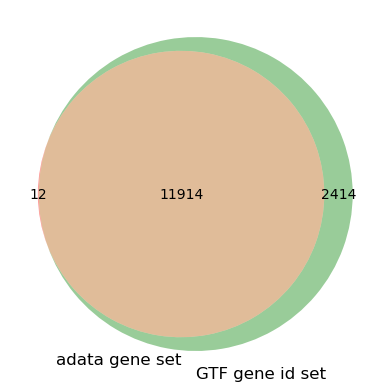

adata gene num: 11926
gtf gene num: 14328
adata ∩ gtf: 11914


In [16]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([Hsal_set, Hsal_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

print(f"adata gene num: {len(Hsal_set)}")
print(f"gtf gene num: {len(Hsal_gid_set)}")

print(f"adata ∩ gtf: {len(Hsal_set & Hsal_gid_set)}")

*H. saltator*: 12 genes of `adata gene set` not in `GTF gene id set`

In [17]:
Hsal_set - Hsal_gid_set

{'Anamorsin',
 'Centrin-1',
 'Fut8',
 'Glomulin',
 'Ickin1-1',
 'Importin-4',
 'LOC112589664-UTR',
 'Traa',
 'Trab',
 'Trehalase',
 'Trnag-ccc',
 'Trypsin-1'}

In [18]:
# manual check using vim:
# Anamorsin GeneID_105189905
# Centrin-1 GeneID_105182209
# Fut8  GeneID_105180734
# Glomulin  GeneID_105186061
# Ickin1-1  GeneID_105192486
# Importin-4    GeneID_105191188
# LOC112589664-UTR  LOC112589664-UTR
# Traa  GeneID_105190403
# Trab  GeneID_105180922
# Trehalase GeneID_105186054
# Trnag-ccc GeneID_109504356
# Trypsin-1 GeneID_105181699
mapping = {
    "Anamorsin": "GeneID_105189905",
    "Centrin-1": "GeneID_105182209",
    "Fut8": "GeneID_105180734",
    "Glomulin": "GeneID_105186061",
    "Ickin1-1": "GeneID_105192486",
    "Importin-4": "GeneID_105191188",
    "LOC112589664-UTR": "LOC112589664-UTR",
    "Traa": "GeneID_105190403",
    "Trab": "GeneID_105180922",
    "Trehalase": "GeneID_105186054",
    "Trnag-ccc": "GeneID_109504356",
    "Trypsin-1": "GeneID_105181699",
}

import re

def resolve_gene_id(idx):
    idx_str = str(idx)
    for key, val in mapping.items():
        # 用正则确保是"单词边界"式匹配，避免子串误匹配
        if re.search(rf'(?<![A-Za-z0-9]){re.escape(key)}(?![A-Za-z0-9])', idx_str):
            return val
    return idx_str

Hsal.var["gene_id"] = [resolve_gene_id(i) for i in Hsal.var.index]

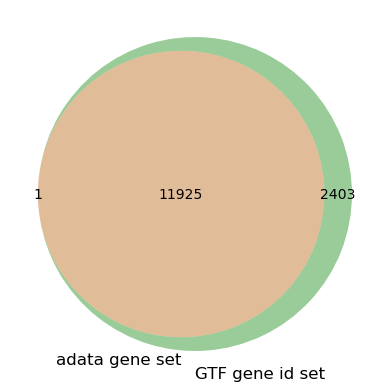

In [19]:
v = venn2([set(Hsal.var["gene_id"].to_list()), Hsal_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

# print(f"adata gene num: {len(set(Hsal.var["gene_id"].to_list()))}")
# print(f"gtf gene num: {len(Hsal_gid_set)}")

# print(f"adata ∩ gtf: {len(set(Hsal.var["gene_id"].to_list()) & Hsal_gid_set)}")

# the "1" is LOC112589664-UTR, I don't know what fucking it is, and why it appear in the UMI count matrix

In [20]:
Hsal.var["origin_index"] = Hsal.var.index
Hsal.var = Hsal.var.set_index("gene_id")
Hsal.var

,origin_index
gene_id,
GeneID_105189905,Anamorsin
GeneID_105182209,Centrin-1
GeneID_105180734,Fut8
GeneID_105186061,Glomulin
GeneID_105192486,Ickin1-1
...,...
LOC105189113,LOC105189113
LOC105191435,LOC105191435
LOC112590349,LOC112590349


In [21]:
Hsal.write_h5ad("./matrix/Hsal50_corrected.h5ad")

# Get gene list for MetaNeighbor

Not all genes in Acer_vs_XXX_121.tsv can be used in MetaNeighbor: 

In [16]:
import scanpy as sc
import pandas as pd

In [30]:
Hsal = sc.read_h5ad("./matrix/Hsal50_corrected.h5ad")

In [18]:
Hsal_set = set(Hsal.var.index)

In [19]:
Acer_vs_Hsal_121 = pd.read_csv("./orthologs/Acer_vs_Hsal_121.tsv", sep="\t")
Hsal_121_set = set(Acer_vs_Hsal_121["Harpegnathos_saltator"].to_list())

Acer_vs_XXX_121 中部分基因可能出现在了原始表达矩阵中，但在质控过程中被过滤掉，因此没有出现在 XXX_set 中，而出现在 XXX_set 中的基因，很多又与 *A. cerana* 无直系同源关系，因此没有出现在 Acer_vs_XXX_121 中

Some genes from Acer_vs_XXX_121 may have been present in the initial expression matrix but were filtered out during quality control—and thus do not appear in XXX_set—whereas many genes found in XXX_set lack direct orthologs in *A. cerana* and therefore do not appear in Acer_vs_XXX_121.

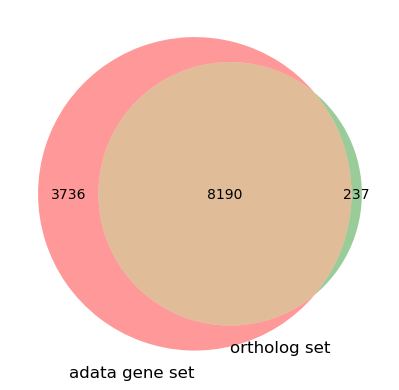

In [20]:
v = venn2([Hsal_set, Hsal_121_set], set_labels=("adata gene set", "ortholog set"))
plt.show()

In [21]:
def get_121_for_mn(
        adata_gid_set: set, 
        ortho_121_set: set, 
        ortho_121_table: pd.DataFrame,
        sp_name: str
    ):
    inter = adata_gid_set & ortho_121_set
    sub_table = ortho_121_table[ortho_121_table[sp_name].isin(inter)]
    return sub_table

In [22]:
Acer_vs_Hsal_121_4mn = get_121_for_mn(Hsal_set, Hsal_121_set, Acer_vs_Hsal_121, "Harpegnathos_saltator")
Acer_vs_Hsal_121_4mn.to_csv("./orthologs/Acer_vs_Hsal_121_4mn.tsv", sep="\t", index=False)

# Prepare .h5ad for MetaNeighbor (R) input:

In [ ]:
# Hsal

AnnData object with n_obs × n_vars = 18583 × 11926
    obs: 'caste', 'experiment', 'replicate', 'sample', 'res.1', 'nCount_RNA', 'nFeature_RNA', 'cluster_name'
    var: 'origin_index'
    obsm: 'pca', 'tsne'
    layers: 'counts', 'data', 'scale.data'

In [ ]:
# # 检查anndata
# import numpy as np
# import pandas as pd
# import scipy.sparse as sp

In [ ]:
# assert "counts" in Hsal.layers, "Hsal.layers['counts'] 不存在"

# counts = Hsal.layers["counts"].tocsr().copy()

# # 先清掉其它 layer，避免后面 subset 时带着 data/scale.data
# Hsal.layers = {}
# Hsal.X = counts

# # =========================================================
# # 2. 检查 X 是否为 raw counts
# # =========================================================
# X = Hsal.X.tocsr()
# d = X.data
# row_sums = np.asarray(X.sum(axis=1)).ravel()
# col_sums = np.asarray(X.sum(axis=0)).ravel()

# print("shape:", X.shape)
# print("dtype:", X.dtype)
# print("min / max:", d.min(), d.max())
# print("all finite:", np.isfinite(d).all())
# print("nonnegative:", (d >= 0).all())
# print("integer-valued:", np.allclose(d, np.round(d)))
# print("zero cells:", int((row_sums == 0).sum()))
# print("zero genes:", int((col_sums == 0).sum()))

# if "nCount_RNA" in Hsal.obs:
#     obs_total = Hsal.obs["nCount_RNA"].values.astype(float)
#     print("max |row_sum - nCount_RNA|:", np.max(np.abs(row_sums - obs_total)))
#     print("allclose:", np.allclose(row_sums, obs_total))

# print("var_names unique:", Hsal.var_names.is_unique)
# print("obs_names unique:", Hsal.obs_names.is_unique)

shape: (18583, 11926)
dtype: float64
min / max: 1.0 176.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 21
max |row_sum - nCount_RNA|: 0.0
allclose: True
var_names unique: True
obs_names unique: True


In [ ]:
# Acer_vs_Hsal_121_4mn

,Orthogroup,Apis_cerana,Harpegnathos_saltator
0,OG0000002,LOC107996633,LOC105188312
1,OG0000007,LOC108001575,LOC105186259
2,OG0000008,LOC108003495,LOC105190164
3,OG0000009,LOC108000539,LOC105191306
5,OG0000010,LOC107995288,LOC105181291
...,...,...,...
8418,OG0010878,LOC107992909,LOC112588612
8422,OG0010897,LOC107993162,LOC112588812
8424,OG0010909,LOC107996162,LOC105182284
8425,OG0010913,LOC133667269,LOC109503586


In [ ]:
# # 删除全零基因，仅保留 Amel & Acer一对一直系同源基因
# Acer_Hsal_121_set = set(Acer_vs_Hsal_121_4mn["Harpegnathos_saltator"].to_list())
# expressed = np.asarray(Hsal.X.sum(axis=0)).ravel() > 0
# in_ortholog = Hsal.var_names.isin(Acer_Hsal_121_set)
# gene_keep = expressed & in_ortholog
# Hsal = Hsal[:, gene_keep].copy()
# Hsal

AnnData object with n_obs × n_vars = 18583 × 8184
    obs: 'caste', 'experiment', 'replicate', 'sample', 'res.1', 'nCount_RNA', 'nFeature_RNA', 'cluster_name'
    var: 'origin_index'
    obsm: 'pca', 'tsne'

In [ ]:
# print(expressed.sum())
# print(in_ortholog.sum())
# print(gene_keep.sum())

11905
8190
8184


In [ ]:

# # =========================================================
# # 4. 清理 cluster_name 标签
# # =========================================================
# Hsal.obs["cluster_name"] = (
#     Hsal.obs["cluster_name"]
#     .astype(str)
#     .str.replace(r"[.\|\s/]+", "_", regex=True)
# )

# # 只保留后续可能用到的 obs 列
# Hsal.obs = Hsal.obs[["cluster_name", "sample", "caste"]].copy()

# Hsal.obs["cluster_name"] = Hsal.obs["cluster_name"].astype("category")
# Hsal.obs["cluster_name"] = (
#     Hsal.obs["cluster_name"].cat.remove_unused_categories()
# )

# # =========================================================
# # 5. 精简对象
# # =========================================================
# Hsal.layers = {}
# Hsal.obsm = {}
# Hsal.varm = {}
# Hsal.obsp = {}
# Hsal.uns = {}
# Hsal.raw = None

In [ ]:
# Hsal

AnnData object with n_obs × n_vars = 18583 × 8184
    obs: 'cluster_name', 'sample', 'caste'
    var: 'origin_index'

In [ ]:
# Hsal.write_h5ad("./matrix/Hsal50_4_MetaNeighboR.h5ad")

# Prepare .h5ad for MetaNeighbor input:

思路：获取 Hsal anndata 对象与 Hsal-Acer 同源基因中 Hsal 部分的基因交集，Acer anndata 对象与 Hsal-Acer 同源基因中 Acer 部分的基因交集。取二者间有同源关系的基因。

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp

In [2]:
Hsal = sc.read_h5ad("./matrix/Hsal50_corrected.h5ad")
Acer = sc.read_h5ad("./matrix/01_Acer_transfromHY.h5ad")

In [3]:
Hsal

AnnData object with n_obs × n_vars = 18583 × 11926
    obs: 'caste', 'experiment', 'replicate', 'sample', 'res.1', 'nCount_RNA', 'nFeature_RNA', 'cluster_name'
    var: 'origin_index'
    obsm: 'pca', 'tsne'
    layers: 'counts', 'data', 'scale.data'

In [4]:
Hsal.obs["cluster_name"].nunique()
# 24个簇，与Acer的约40个簇差得很多，但是也能跑MetaNeighbor

24

In [5]:
counts = Hsal.layers["counts"].tocsr().copy()
Hsal.X = counts

X = Hsal.X.tocsr()
d = X.data
row_sums = np.asarray(X.sum(axis=1)).ravel()
col_sums = np.asarray(X.sum(axis=0)).ravel()

print("shape:", X.shape)
print("dtype:", X.dtype)
print("min / max:", d.min(), d.max())
print("all finite:", np.isfinite(d).all())
print("nonnegative:", (d >= 0).all())
print("integer-valued:", np.allclose(d, np.round(d)))
print("zero cells:", int((row_sums == 0).sum()))
print("zero genes:", int((col_sums == 0).sum()))

if "nCount_RNA" in Hsal.obs:
    obs_total = Hsal.obs["nCount_RNA"].values.astype(float)
    print("max |row_sum - nCount_RNA|:", np.max(np.abs(row_sums - obs_total)))
    print("allclose:", np.allclose(row_sums, obs_total))

print("var_names unique:", Hsal.var_names.is_unique)
print("obs_names unique:", Hsal.obs_names.is_unique)

shape: (18583, 11926)
dtype: float64
min / max: 1.0 176.0
all finite: True
nonnegative: True
integer-valued: True
zero cells: 0
zero genes: 21
max |row_sum - nCount_RNA|: 0.0
allclose: True
var_names unique: True
obs_names unique: True


In [6]:
Acer_vs_Hsal_121 = pd.read_csv("./orthologs/Acer_vs_Hsal_121_4mn.tsv", sep="\t")
Acer_vs_Hsal_121

,Orthogroup,Apis_cerana,Harpegnathos_saltator
0,OG0000002,LOC107996633,LOC105188312
1,OG0000007,LOC108001575,LOC105186259
2,OG0000008,LOC108003495,LOC105190164
3,OG0000009,LOC108000539,LOC105191306
4,OG0000010,LOC107995288,LOC105181291
...,...,...,...
8185,OG0010878,LOC107992909,LOC112588612
8186,OG0010897,LOC107993162,LOC112588812
8187,OG0010909,LOC107996162,LOC105182284
8188,OG0010913,LOC133667269,LOC109503586


In [ ]:
def get_common_121_for_mn(ortho, adatas):
    keep = np.ones(len(ortho), dtype=bool)
    for col, ad in adatas.items():
        keep &= ortho[col].isin(ad.var_names).to_numpy()
    return ortho.loc[keep].drop_duplicates().reset_index(drop=True)


pairs = get_common_121_for_mn(
    Acer_vs_Hsal_121,
    {"Harpegnathos_saltator": Hsal, "Apis_cerana": Acer},
)

# 用 list 索引会同时完成“取子集 + 按 pairs 顺序对齐”
Hsal4MN = Hsal[:, pairs["Harpegnathos_saltator"].tolist()].copy()
Acer4MN = Acer[:, pairs["Apis_cerana"].tolist()].copy()

# 可选：过滤两物种中全零的基因
ea = np.asarray(Hsal4MN.X.sum(axis=0)).ravel() > 0
ec = np.asarray(Acer4MN.X.sum(axis=0)).ravel() > 0
keep = ea & ec
pairs = pairs[keep].reset_index(drop=True)
Hsal4MN = Hsal4MN[:, keep].copy()
Acer4MN = Acer4MN[:, keep].copy()

assert Hsal4MN.n_vars == Acer4MN.n_vars == len(pairs)

In [8]:
print(Hsal4MN.shape, Acer4MN.shape)

(18583, 8073) (58166, 8073)


In [9]:
Hsal4MN.write_h5ad("./matrix/MN_input/Hsal4MN_8073.h5ad")
Acer4MN.write_h5ad("./matrix/MN_input/Acer4MN_8073.h5ad")